# P2P Fairness Analysis

Workflow:
1. Load scenario data + saved solver results
2. Compute no-trade baseline
3. Compute savings $d_i = (J_i^{nt} - J_i^{SO}) / J_i^{nt}$
4. Fairness metrics: SW, TW, MM, Jain's, Var
5. Investigate P1 negative savings

## 1. Setup

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
import sys

# Point to your repo
REPO = Path('/Users/catharinahente/Documents/Github/p2p-energy-trading-illustrative')
sys.path.insert(0, str(REPO))

from scenarios import make_scenario
from metrics  import no_trade_costs, savings, sw, tw, mm, jains, var_savings

plt.rcParams.update({
    'font.family':       'sans-serif',
    'font.size':         9,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'pdf.fonttype':      42,
})

C = ['#2F6FA3','#C65D3B','#2E6F52','#B5720A']   # prosumer colours
SEASON = 'winter'
CASES  = ['centralized', 'distributed', 'centralized_network']

## 2. Load scenario data and saved results

In [2]:
data = make_scenario(SEASON, seed=42)
N    = len(data['demand'])
T    = len(data['buy_price'])
dt   = data['dt']
t    = np.arange(T) * dt
names = data['prosumer_names']
print(f'N={N} prosumers  T={T} steps  dt={dt}h  season={SEASON}')
for i, name in enumerate(names):
    print(f'  P{i+1}: {name}')

Building winter scenario (T=96, dt=0.25h)...
  P1: Residential ++ (bus 5)
    HP: Air_Alternative_1 (Air alternative, Hanover)
  P2: Office building (bus 11)
    ⚠ No EV activity detected — using business hours fallback
  P3: Residential HP only (bus 17)
    HP: Air_Semi-Parallel_1 (Air semi-parallel, Hanover)
  P4: Residential PV only (bus 32)
  Done. N=4, T=96, max_demand=6.6 kW
N=4 prosumers  T=96 steps  dt=0.25h  season=winter
  P1: Residential ++
  P2: Office building
  P3: Residential HP only
  P4: Residential PV only


In [3]:
def load_result(name):
    p = REPO / 'results' / name / 'summary.json'
    if not p.exists():
        print(f'  ✗ {name} not found')
        return None
    raw = json.loads(p.read_text())
    trades = {}
    for k, v in raw['trades'].items():
        ij, t_ = k.split('@')
        i_, j_ = ij.split('->')
        trades[(int(i_), int(j_), int(t_))] = v
    raw['trades'] = trades
    raw['costs']  = np.array(raw['costs'])
    print(f'  ✓ {name}  total={sum(raw["costs"]):.4f} EUR')
    return raw

results = {}
for case in CASES:
    r = load_result(case)
    if r is not None:
        results[case] = r

  ✓ centralized  total=58.2176 EUR
  ✓ distributed  total=58.2176 EUR
  ✓ centralized_network  total=58.2176 EUR


## 3. No-trade baseline

In [4]:
J_nt = no_trade_costs(data)
print(f'\nΣ J_nt = {J_nt.sum():.4f} EUR')
if 'centralized' in results:
    J_so = results['centralized']['costs']
    print(f'Σ J_SO = {J_so.sum():.4f} EUR')
    print(f'Δ      = {J_nt.sum() - J_so.sum():.4f} EUR  (trading saves this much in total)')

Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2806500
Academic license 2806500 - for non-commercial use only - registered to ch___@ethz.ch
  P1 no-trade cost: 6.4699 EUR
  P2 no-trade cost: 38.0269 EUR
  P3 no-trade cost: 3.3480 EUR
  P4 no-trade cost: 11.0328 EUR

Σ J_nt = 58.8776 EUR
Σ J_SO = 58.2176 EUR
Δ      = 0.6600 EUR  (trading saves this much in total)


## 4. Cost comparison — no-trade vs social optimum

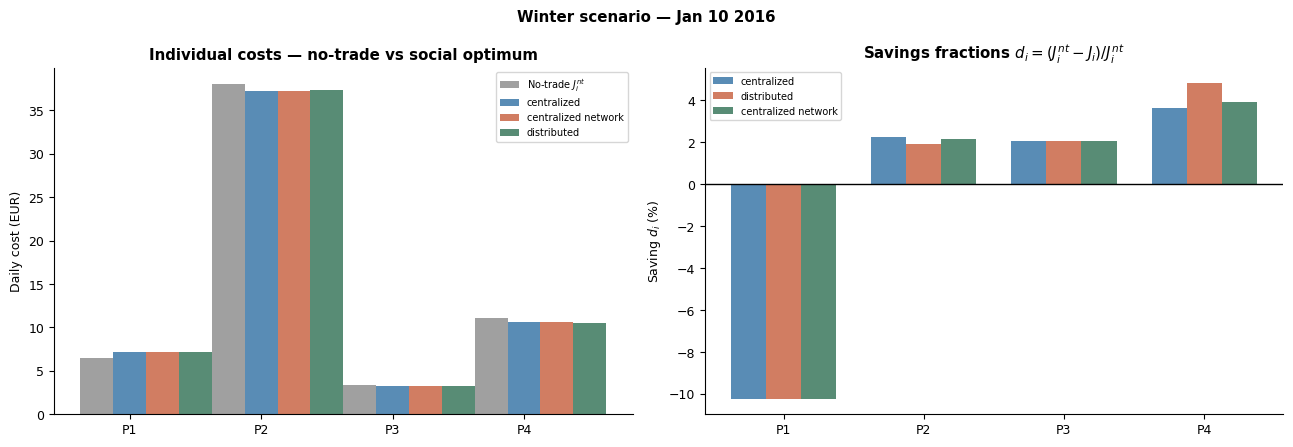

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# ── Left: absolute costs ──────────────────────────────────────────────────────
ax = axes[0]
x  = np.arange(N)
w  = 0.25
ax.bar(x - w, J_nt, width=w, color='#888888', alpha=0.8, label='No-trade $J_i^{nt}$')
for ci, (case, ls) in enumerate(zip(
        ['centralized','centralized_network','distributed'],
        ['-','--',':.'])):
    if case not in results: continue
    ax.bar(x + ci*w, results[case]['costs'], width=w,
           color=C[ci], alpha=0.8, label=case.replace('_',' '))
ax.set_xticks(x)
ax.set_xticklabels([f'P{i+1}' for i in range(N)])
ax.set_ylabel('Daily cost (EUR)')
ax.set_title('Individual costs — no-trade vs social optimum', fontweight='bold')
ax.legend(fontsize=7)
ax.axhline(0, color='k', lw=0.4)

# ── Right: savings d_i ────────────────────────────────────────────────────────
ax = axes[1]
for ci, case in enumerate(['centralized','distributed','centralized_network']):
    if case not in results: continue
    d = savings(results[case], J_nt)
    ax.bar(x + (ci-1)*w, d*100, width=w, color=C[ci],
           alpha=0.8, label=case.replace('_',' '))
ax.axhline(0, color='k', lw=1.0)
ax.set_xticks(x)
ax.set_xticklabels([f'P{i+1}' for i in range(N)])
ax.set_ylabel('Saving $d_i$ (%)')
ax.set_title('Savings fractions $d_i = (J_i^{nt} - J_i) / J_i^{nt}$', fontweight='bold')
ax.legend(fontsize=7)

plt.suptitle(f'Winter scenario — Jan 10 2016', fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Fairness metrics table

In [6]:
rows = []
for case in CASES:
    if case not in results: continue
    J_so = results[case]['costs']
    d    = savings(results[case], J_nt)
    rows.append({
        'Case':   case.replace('_',' '),
        'Σ J_SO': round(J_so.sum(), 4),
        'TW (%)': round(tw(J_nt, J_so)*100, 4),
        'SW (Σd)':round(sw(d), 4),
        'MM':     round(mm(d), 4),
        "Jain's": round(jains(d), 4),
        'Var':    round(var_savings(d), 6),
    })

df = pd.DataFrame(rows).set_index('Case')
print('Fairness metrics')
print('─' * 65)
print('Note: TW and Σ J_SO operate on raw EUR costs (CUC).')
print('      MM, Jain, Var operate on savings d_i (CUC on d_i).')
print('      Jain range [1/N,1] only valid when all d_i ≥ 0.')
print('─' * 65)
display(df)

Fairness metrics
─────────────────────────────────────────────────────────────────
Note: TW and Σ J_SO operate on raw EUR costs (CUC).
      MM, Jain, Var operate on savings d_i (CUC on d_i).
      Jain range [1/N,1] only valid when all d_i ≥ 0.
─────────────────────────────────────────────────────────────────


,Σ J_SO,TW (%),SW (Σd),MM,Jain's,Var
Case,,,,,,
centralized,58.2176,1.121,-0.0227,-0.1022,0.0101,0.003141
distributed,58.2176,1.121,-0.0144,-0.1022,0.0039,0.003371
centralized network,58.2176,1.121,-0.0209,-0.1022,0.0085,0.003185


## 6. Investigate P1 negative savings

P1 (Residential ++) has $d_1 < 0$ — it pays **more** with trading than without.
Here we compare its dispatch in the no-trade and social optimum cases.

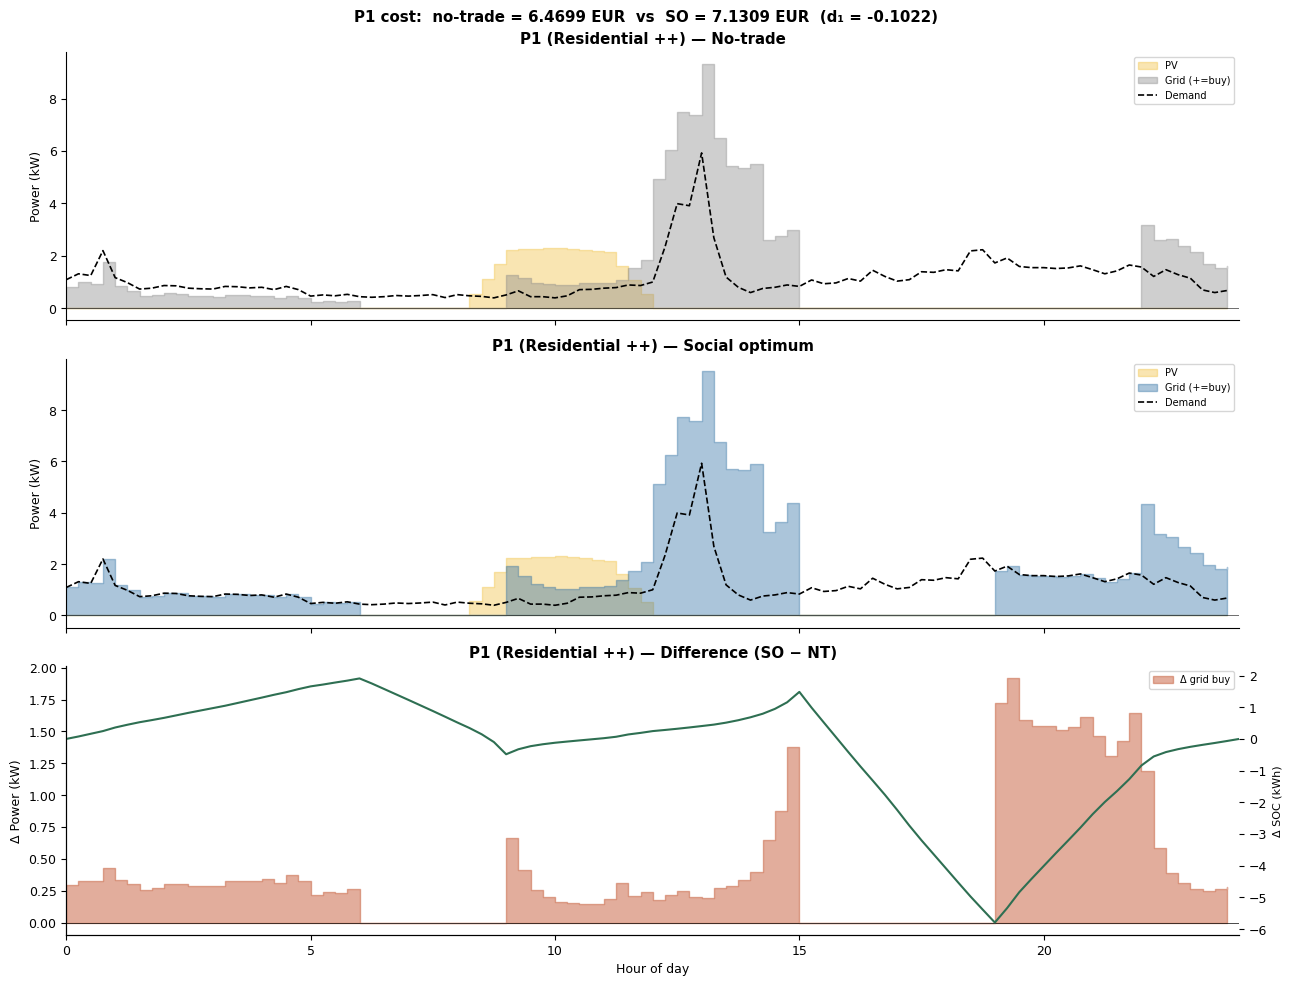

In [7]:
from algo import centralized

# Solve no-trade for P1 and store full result
data_nt = {**data, 'edges': []}
result_nt = centralized(data_nt)
result_so = results.get('centralized')

if result_so is None:
    print('Run centralized case in main.py first')
else:
    i = 0   # P1
    fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

    def _arr(result, key, i):
        v = result.get(key)
        if v is None: return np.zeros(T)
        return np.array(v)[i] if hasattr(v, '__len__') and len(np.array(v).shape) > 1 else np.zeros(T)

    for ax, (label, result, color) in zip(
        axes,
        [('No-trade', result_nt, '#888888'),
         ('Social optimum', result_so, C[0]),
         ('Difference (SO − NT)', None, C[1])]):

        demand = np.array(data['demand'][i])
        gen    = np.array(data['generation'][i])

        if label == 'Difference (SO − NT)':
            buy_nt = _arr(result_nt, 'buy', i)
            buy_so = _arr(result_so, 'buy', i)
            ax.fill_between(t, 0, buy_so - buy_nt,
                            step='post', alpha=0.5, color=C[1],
                            label='Δ grid buy')
            soc_nt = np.array(result_nt.get('soc', np.zeros((N, T+1))))[i]
            soc_so = np.array(result_so.get('soc', np.zeros((N, T+1))))[i]
            t_soc = np.arange(T+1)*dt
            ax2 = ax.twinx()
            ax2.plot(t_soc, soc_so - soc_nt, color='#2E6F52', lw=1.5,
                     label='Δ BESS SOC')
            ax2.set_ylabel('Δ SOC (kWh)', fontsize=8)
            ax2.spines['top'].set_visible(False)
            ax.axhline(0, color='k', lw=0.5)
            ax.set_ylabel('Δ Power (kW)')
        else:
            buy  = _arr(result, 'buy', i)
            sell = _arr(result, 'sell', i)
            chrg = _arr(result, 'charge', i)
            disc = _arr(result, 'discharge', i)
            net_grid = buy - sell
            ax.fill_between(t, 0, gen,      step='post', alpha=0.4,
                            color='#F0C040', label='PV')
            ax.fill_between(t, 0, net_grid, step='post', alpha=0.4,
                            color=color, label='Grid (+=buy)')
            ax.plot(t, demand, color='k', lw=1.2, ls='--', label='Demand')
            ax.axhline(0, color='k', lw=0.4)
            ax.set_ylabel('Power (kW)')

        ax.set_title(f'P1 ({names[0]}) — {label}', fontweight='bold')
        ax.legend(fontsize=7, loc='upper right')
        ax.set_xlim(0, T*dt)

    axes[-1].set_xlabel('Hour of day')
    plt.suptitle(
        f'P1 cost:  no-trade = {result_nt["costs"][i]:.4f} EUR  '
        f'vs  SO = {result_so["costs"][i]:.4f} EUR  '
        f'(d₁ = {savings(result_so, J_nt)[i]:.4f})',
        fontweight='bold')
    plt.tight_layout()
    plt.show()

## 7. Cost breakdown — what drives P1's higher cost with trading?

In [8]:
if result_so is not None:
    i = 0
    for label, result in [('No-trade', result_nt), ('Social optimum', result_so)]:
        buy  = np.array(result.get('buy',  np.zeros((N,T))))[i]
        sell = np.array(result.get('sell', np.zeros((N,T))))[i]
        chrg = np.array(result.get('charge', np.zeros((N,T))))[i]
        disc = np.array(result.get('discharge', np.zeros((N,T))))[i]
        ev_c = np.array(result.get('ev_charge', np.zeros((N,T))))[i]
        ev_d = np.array(result.get('ev_discharge', np.zeros((N,T))))[i]
        bp   = np.array(data['buy_price'])
        sp   = np.array(data['sell_price'])

        cost_buy  = float(np.sum(bp * buy  * dt))
        cost_sell = float(np.sum(sp * sell * dt))
        cost_bess = float(np.sum((chrg + disc) * dt) * data['battery_cost'])
        cost_ev   = float(np.sum((ev_c + ev_d) * dt) * data['ev_cost'])
        cost_tot  = result['costs'][i]

        print(f'\nP1 — {label}  (total = {cost_tot:.4f} EUR)')
        print(f'  Grid buy:       {cost_buy:>8.4f} EUR')
        print(f'  Grid sell:     -{cost_sell:>8.4f} EUR')
        print(f'  BESS wear:      {cost_bess:>8.4f} EUR')
        print(f'  EV wear:        {cost_ev:>8.4f} EUR')
        # Remainder is trade fees
        other = cost_tot - cost_buy + cost_sell - cost_bess - cost_ev
        print(f'  Trade fees etc: {other:>8.4f} EUR')


P1 — No-trade  (total = 6.4699 EUR)
  Grid buy:         6.3042 EUR
  Grid sell:     -  0.0000 EUR
  BESS wear:        0.1345 EUR
  EV wear:          0.0313 EUR
  Trade fees etc:   0.0000 EUR

P1 — Social optimum  (total = 7.1309 EUR)
  Grid buy:         8.7799 EUR
  Grid sell:     -  0.0000 EUR
  BESS wear:        0.1577 EUR
  EV wear:          0.0313 EUR
  Trade fees etc:  -1.8380 EUR
